In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import StandardScaler


header = ['comment_id', 'text', 'date', 'song', 'artist', 'kendrick_score', 'drake_score']
dataset = pd.read_csv(filepath_or_buffer='./cleaned_comments/cleaned_comments.csv',  delimiter=',', names=header, skiprows=1)
dataset

,comment_id,text,date,song,artist,kendrick_score,drake_score
0,Ugzc5Srhx8p6qzdSjvB4AaABAg,Kendrick responded so fast I didnt know Drake ...,2024-05-04 12:59:37+00:00,Family_Matters,BagOnly_Drake,2,-1
1,UgxGl-mJYHo4mzjNy0R4AaABAg,Beat switches each time a different ghost writ...,2024-05-04 08:41:23+00:00,Family_Matters,BagOnly_Drake,0,-2
2,Ugw8sI-rRjgKXTUCBFV4AaABAg,Kendrick had a diss ready for this song not ev...,2024-05-04 05:18:35+00:00,Family_Matters,BagOnly_Drake,2,0
3,UgzkG6vRyh2O9FOlnJR4AaABAg,Imagine sitting down in a group and writing th...,2024-05-04 17:04:41+00:00,Family_Matters,BagOnly_Drake,1,-1
4,UgyRU5sH2RugrPSNal94AaABAg,ngl Drake's melody is fire\n\nbut Kendrick's l...,2024-05-05 06:28:06+00:00,Family_Matters,BagOnly_Drake,3,2
...,...,...,...,...,...,...,...
5693,Ugy_pfO-XFQhO5gGBA94AaABAg,"''I agree'' with you, this track is so deep th...",2024-05-05 10:59:39+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5694,UgwKaRbSQ7CT8Id9UlJ4AaABAg,"It's like y'all came in expecting a comedy, wa...",2024-05-04 21:19:33+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,-3
5695,UgwKuRsl6mRT319BxZB4AaABAg,Kendrick gave you all the bars and metaphors y...,2024-05-05 05:00:26+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5696,UgxGzHrFJUiB4cJv-7t4AaABAg,Never thought I would think this channel would...,2024-05-04 22:54:04+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,2,-2


In [3]:
signs = {1: '+', 0: 'neutral', -1: '-'}

k_signs = np.sign(dataset['kendrick_score']).astype(int).map(signs)
d_signs = np.sign(dataset['drake_score']).astype(int).map(signs)

youtube_comment_texts = dataset['text'].values
youtube_comment_labels = ('K ' + k_signs + ', D ' + d_signs).values

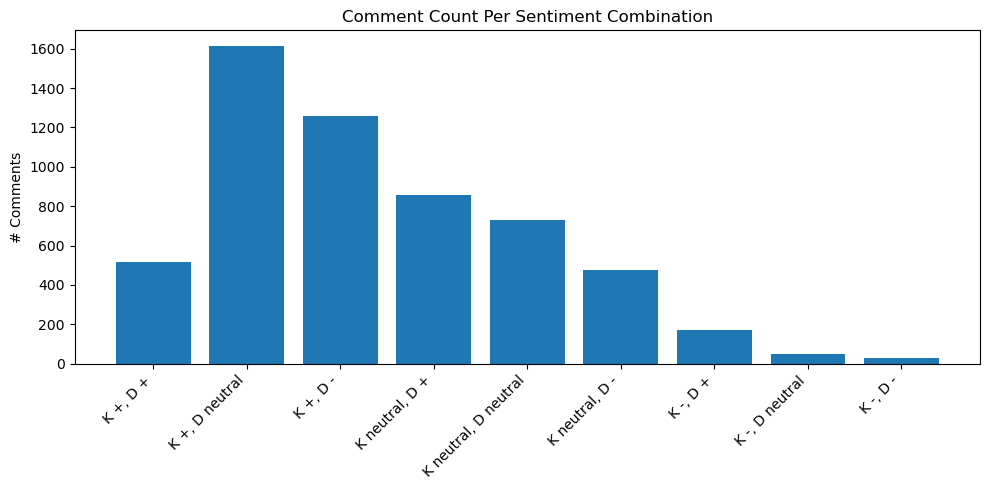

In [4]:
order = ['+', 'neutral', '-']
all_labels = [f"K {k}, D {d}" for k in order for d in order]

counts = pd.Series(youtube_comment_labels).value_counts().reindex(all_labels, fill_value=0)

plt.figure(figsize=(10, 5))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=45, ha='right')
plt.ylabel('# Comments')
plt.title('Comment Count Per Sentiment Combination')
plt.tight_layout()
plt.show()

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

#removing any category which only has 1 data point in it -- train_test_split cannot split a category with only 1 dp
labels = pd.Series(youtube_comment_labels)
label_sizes = labels.map(labels.value_counts()).values
keep = label_sizes >= 2
youtube_comment_texts = youtube_comment_texts[keep]
youtube_comment_labels = youtube_comment_labels[keep]


#extracting 4.96% of the comments for the testing set (282)
X_train, X_test, y_train, y_test = train_test_split(
    youtube_comment_texts,
    youtube_comment_labels,
    test_size=0.0496,
    random_state=38
)

print(X_train)

#Creating the model
vec = CountVectorizer()
X = vec.fit_transform(X_train)
model = MultinomialNB(alpha=1)
model.fit(X, y_train)

#predicting on a new message
X_test_vec = vec.transform(X_test)
y_pred = model.predict(X_test_vec)

print(classification_report(y_test, y_pred, zero_division=0))

['Dear Adonis \nDear Sandra \nDear Dennis \nDear Baby Girl \nDear Aubrey \n\nthe whole fam 😂😂😂'
 'Did these dudes just say this man sounds “childish”… WOW lol this whole reaction is actually kinda hilarious because they really think they sound so elevated but damn near every bar went over their heads. Obv Music is subjective but my goodness I’ve seen Drake fans react to this and they are in awe because every part of this song is musical master class.'
 "When I show up it's motion picture blockbuster. The goat with the golden pen the top toucher😮"
 ...
 'These dudes crazy!  They don’t even realize what they’re listening to.  This is going to age badddddd'
 "Oh we're going to have some fun alright..."
 "He thinks he's Eminem after naming all these people? Don't think it comes close to anything Kendrick would write in a whole song. Also, 20v1 sounds a bit weird when it's probably 20v20 with all the writers he has."]
                      precision    recall  f1-score   support

          

In [25]:
train_df = pd.DataFrame({'text': X_train, 'label': y_train, 'set': 'train'})
test_df = pd.DataFrame({'text': X_test, 'label': y_test, 'set': 'test'})

train_df

,text,label,set
0,Dear Adonis \nDear Sandra \nDear Dennis \nDear...,"K +, D neutral",train
1,Did these dudes just say this man sounds “chil...,"K +, D neutral",train
2,When I show up it's motion picture blockbuster...,"K neutral, D neutral",train
3,First drake song I unironically listen to and ...,"K neutral, D -",train
4,That whistle is crazy with future,"K neutral, D neutral",train
...,...,...,...
5410,wow! This is deep. This is a true Artist and b...,"K +, D -",train
5411,6:16 LA after Euphoria? yah back to back i lik...,"K +, D neutral",train
5412,These dudes crazy! They don’t even realize wh...,"K +, D neutral",train
5413,Oh we're going to have some fun alright...,"K +, D -",train


In [26]:
test_df

,text,label,set
0,"In the beginning verse, K-Dot is rapping from ...","K +, D -",test
1,Is it me or does Drake’s flow seem a bit rushe...,"K neutral, D -",test
2,Kendrick won but this the only good drake diss,"K +, D +",test
3,"I love that “God, my confession is yours, but ...","K +, D neutral",test
4,Crazy how he literally predicted all the bull...,"K +, D -",test
...,...,...,...
278,The fact that he got the Alchemist to do the p...,"K +, D neutral",test
279,"J Cole, now we understand. Much peace to you. ...","K +, D neutral",test
280,These bots are big mad. Kendrick murdered drak...,"K +, D -",test
281,Kendrick accused Drake of all the worst crimes...,"K +, D -",test


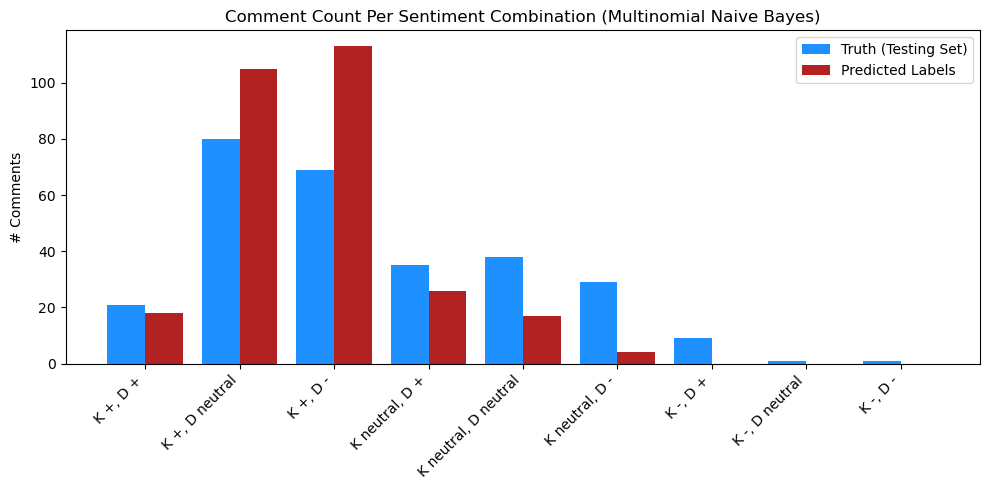

In [20]:
actual_counts = pd.Series(y_test).value_counts().reindex(all_labels, fill_value=0)
pred_counts =pd.Series(y_pred).value_counts().reindex(all_labels, fill_value=0)

bar_width = 0.4
pos = np.arange(len(all_labels))

plt.figure(figsize=(10, 5))
plt.bar(pos - bar_width/2, actual_counts.values, width=bar_width, color='dodgerblue', label='Truth (Testing Set)')
plt.bar(pos + bar_width/2, pred_counts.values, width=bar_width, color='firebrick', label='Predicted Labels')
plt.xticks(pos, all_labels, rotation=45, ha='right')
plt.ylabel('# Comments')
plt.title('Comment Count Per Sentiment Combination (Multinomial Naive Bayes)')
plt.legend()
plt.tight_layout()
plt.show()

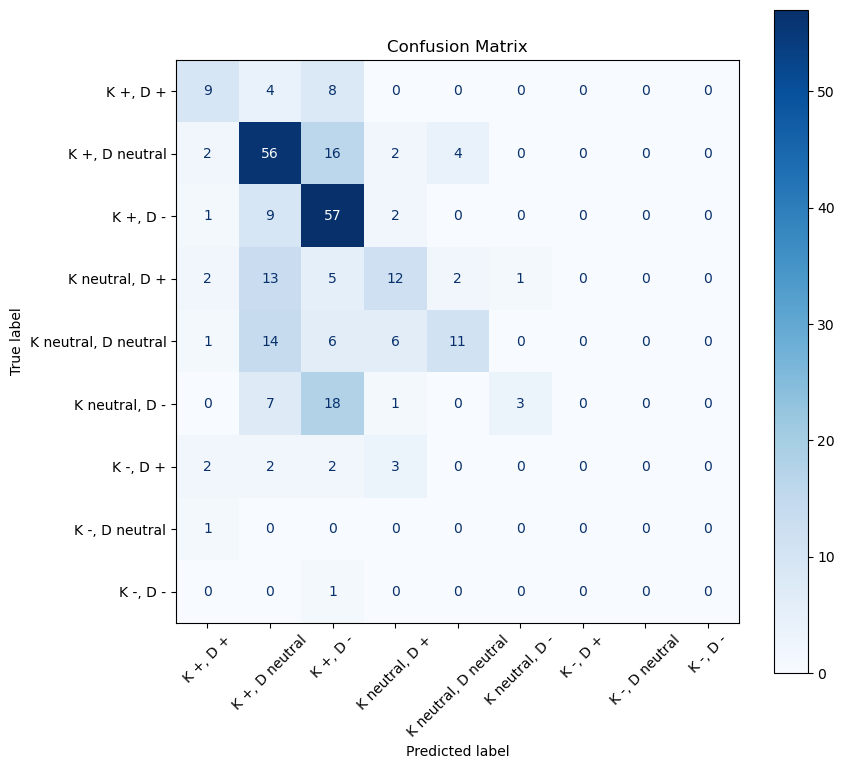

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=all_labels)

fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=all_labels)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=True)
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

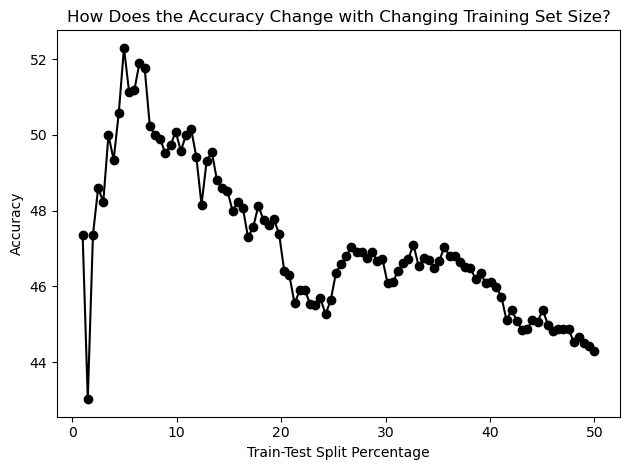

In [ ]:
#how does the accuracy change with test size? what is the optimal test size?


ttsplit_percentage = np.linspace(0.01, 0.5, num=100, endpoint=True)
accuracies = []

for split_percentage in ttsplit_percentage:
    #extracting 5% of the comments for the testing set (285)
    X_train, X_test, y_train, y_test = train_test_split(
        youtube_comment_texts,
        youtube_comment_labels,
        test_size=split_percentage,
        random_state=38
    )

    #Creating the model
    vec = CountVectorizer()
    X = vec.fit_transform(X_train)
    model = MultinomialNB(alpha=1)
    model.fit(X, y_train)

    #predicting on a new message
    X_test_vec = vec.transform(X_test)
    y_pred = model.predict(X_test_vec)

    report = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
    # print(report['accuracy'])
    accuracies.append(float(report['accuracy'])*100)


plt.figure()
plt.plot(ttsplit_percentage*100, accuracies, marker='o', ls='-', c='black')
plt.ylabel("Accuracy")
plt.xlabel("Train-Test Split Percentage")
plt.title("How Does the Accuracy Change with Changing Training Set Size?")
plt.tight_layout()
plt.grid(True)
plt.show()


In [16]:
idx = np.argmax(accuracies)
print(f'Accuracy is highest when the test data is {(ttsplit_percentage[idx]*100):.2f}% at an accuracy of {accuracies[idx]:.2f}%')

Accuracy is highest when the test data is 4.96% at an accuracy of 52.30%
